## EN3160 Assignment 3 on Neural Networks

## 230680M - W.M.H. Wanigasundara

GitHub: [https://github.com/HasinduWanigasundara/Neural_Networks](https://github.com/HasinduWanigasundara/Neural_Networks)

## Problem 1

PyTorch: 2.8.0+cu126 | Device: cuda
Epoch 1/10, Loss: 1.7913
Epoch 2/10, Loss: 1.6661
Epoch 3/10, Loss: 1.6071
Epoch 4/10, Loss: 1.5634
Epoch 5/10, Loss: 1.5239
Epoch 6/10, Loss: 1.4898
Epoch 7/10, Loss: 1.4616
Epoch 8/10, Loss: 1.4349
Epoch 9/10, Loss: 1.4121
Epoch 10/10, Loss: 1.3913

Training Accuracy: 53.91%
Test Accuracy: 47.69%


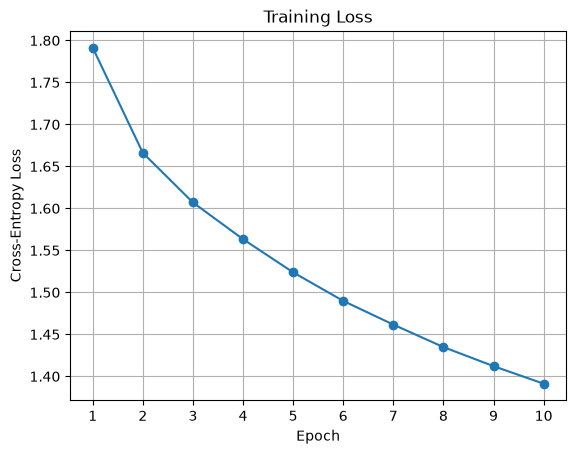

In [1]:
import torch, torchvision, matplotlib.pyplot as plt
import torch.nn.functional as F
import torchvision.transforms as transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

# 1. Load CIFAR-10
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,) * 3, (0.5,) * 3)])
trainset = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=50, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=50, shuffle=False)

# 2. Parameters: input -> 100 sigmoid hidden units -> 10 outputs (Xavier initialisation)
Din, H, K = 3 * 32 * 32, 100, 10
W1, b1 = torch.randn(Din, H, device=device) * (2 / (Din + H)) ** 0.5, torch.zeros(H, device=device)
W2, b2 = torch.randn(H, K, device=device) * (2 / (H + K)) ** 0.5, torch.zeros(K, device=device)
epochs, lr, lr_decay, loss_history = 10, 0.1, 0.9, []

def forward(X):
    hidden = torch.sigmoid(X @ W1 + b1)
    return hidden, hidden @ W2 + b2

# 3. Training with manual forward pass and backpropagation
for epoch in range(epochs):
    running_loss = 0.0
    for inputs, labels in trainloader:
        X, labels = inputs.flatten(1).to(device), labels.to(device)
        N = X.shape[0]
        hidden, logits = forward(X)

        # Softmax cross-entropy loss (log-sum-exp for numerical stability)
        log_probs = logits - torch.logsumexp(logits, dim=1, keepdim=True)
        loss = -log_probs[torch.arange(N, device=device), labels].mean()
        running_loss += loss.item()

        # Backpropagation
        d_logits = (log_probs.exp() - F.one_hot(labels, K).float()) / N
        dW2, db2 = hidden.T @ d_logits, d_logits.sum(0)
        d_hidden = (d_logits @ W2.T) * hidden * (1 - hidden)  # sigmoid derivative
        dW1, db1 = X.T @ d_hidden, d_hidden.sum(0)

        # Gradient descent update
        for param, grad in zip((W1, b1, W2, b2), (dW1, db1, dW2, db2)):
            param -= lr * grad

    loss_history.append(running_loss / len(trainloader))
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")
    lr *= lr_decay

# 4. Accuracy
@torch.no_grad()
def accuracy(loader):
    correct = sum((forward(x.flatten(1).to(device))[1].argmax(1).cpu() == y).sum().item() for x, y in loader)
    return 100 * correct / len(loader.dataset)

print(f"\nTraining Accuracy: {accuracy(trainloader):.2f}%\nTest Accuracy: {accuracy(testloader):.2f}%")

# 5. Plot training loss
plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.gca().set(xlabel="Epoch", ylabel="Cross-Entropy Loss", title="Training Loss", xticks=range(1, epochs + 1))
plt.grid(True)
plt.show()

**Changes to Listing 1.**

- **(a)** A hidden layer of 100 sigmoid units was added (3072 → 100 → 10, 308,310 parameters). Backpropagation goes through the sigmoid using $\sigma'(z) = h(1-h)$.
- **(b)** The MSE loss was replaced by softmax cross-entropy, computed manually. Its output gradient is $\frac{1}{N}(\text{softmax}(z) - y_{\text{onehot}})$.
- Xavier initialisation and lr = 0.1 (decay 0.9) replace the listing's `std = 1e-5` and `lr = 2e-6`, which are too small for the deeper network to learn in 10 epochs.

**(c) Results after 10 epochs.**

| Training Acc | Test Acc | Loss (epoch 1 → 10) |
|---|---|---|
| 53.91% | 47.69% | 1.791 → 1.391 |

**Interpretation.**

- The test accuracy is well above chance (10%). The hidden layer adds non-linear capacity that the single-layer Listing 1 does not have.
- The loss is still decreasing at epoch 10, so the network has not converged.
- The 6-point train–test gap shows mild overfitting, since there is no regularisation.
- Flattening the image discards spatial structure, and sigmoid units saturate. CNNs (Problem 2) address both with shared convolutional weights and ReLU.

## Problem 2

LeNet-5 | Epoch 1/10 | Train Loss: 0.1029 | Train Acc: 97.06% | Test Loss: 0.0995 | Test Acc: 97.02%
LeNet-5 | Epoch 2/10 | Train Loss: 0.0567 | Train Acc: 98.27% | Test Loss: 0.0594 | Test Acc: 98.17%
LeNet-5 | Epoch 3/10 | Train Loss: 0.0493 | Train Acc: 98.47% | Test Loss: 0.0545 | Test Acc: 98.25%
LeNet-5 | Epoch 4/10 | Train Loss: 0.0314 | Train Acc: 99.07% | Test Loss: 0.0432 | Test Acc: 98.61%
LeNet-5 | Epoch 5/10 | Train Loss: 0.0238 | Train Acc: 99.29% | Test Loss: 0.0385 | Test Acc: 98.75%
LeNet-5 | Epoch 6/10 | Train Loss: 0.0213 | Train Acc: 99.33% | Test Loss: 0.0389 | Test Acc: 98.80%
LeNet-5 | Epoch 7/10 | Train Loss: 0.0213 | Train Acc: 99.31% | Test Loss: 0.0381 | Test Acc: 98.81%
LeNet-5 | Epoch 8/10 | Train Loss: 0.0148 | Train Acc: 99.59% | Test Loss: 0.0369 | Test Acc: 98.80%
LeNet-5 | Epoch 9/10 | Train Loss: 0.0108 | Train Acc: 99.70% | Test Loss: 0.0375 | Test Acc: 98.91%
LeNet-5 | Epoch 10/10 | Train Loss: 0.0121 | Train Acc: 99.62% | Test Loss: 0.0407 | Test A

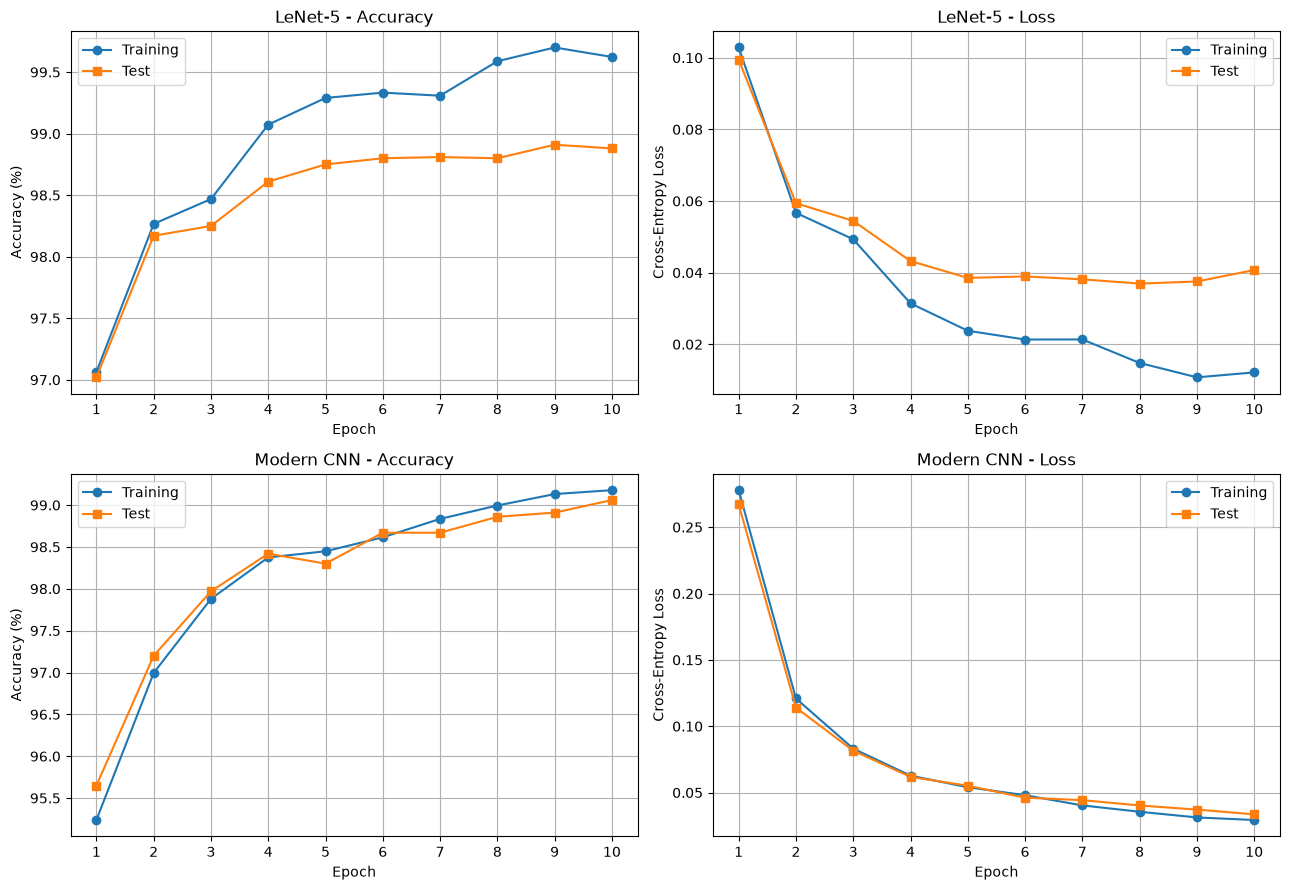

LeNet-5: 98.88% correct | most frequent errors (actual->predicted): 7->2 (9), 9->3 (8), 9->4 (7)
Modern CNN: 99.06% correct | most frequent errors (actual->predicted): 9->4 (8), 0->6 (8), 3->5 (5)


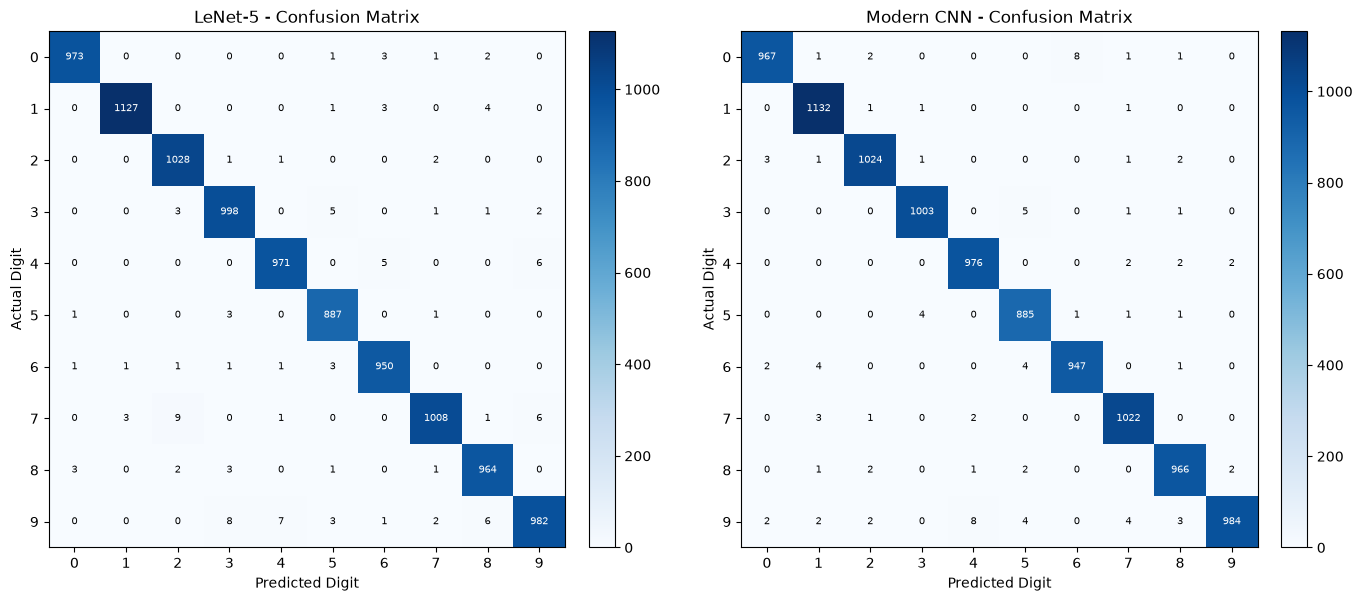

In [2]:
import torch, torch.nn as nn, torchvision, matplotlib.pyplot as plt
import torchvision.transforms as transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
epochs, num_classes = 10, 10

transform = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))])
loaders = {split: torch.utils.data.DataLoader(
               torchvision.datasets.MNIST("./data", train=(split == "train"), download=True, transform=transform),
               batch_size=128, shuffle=(split == "train"))
           for split in ["train", "test"]}

# (a) LeNet-5
lenet = nn.Sequential(
    nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),   # 32x32 -> 28x28 -> 14x14
    nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2),  # 14x14 -> 10x10 -> 5x5
    nn.Flatten(), nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
    nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, num_classes))

# (b) Modern small CNN: 3 conv layers with batch normalisation and dropout
def conv_block(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU()]

cnn = nn.Sequential(
    *conv_block(1, 32), nn.MaxPool2d(2), nn.Dropout2d(0.10),
    *conv_block(32, 64), nn.MaxPool2d(2), nn.Dropout2d(0.15),
    *conv_block(64, 128), nn.AdaptiveAvgPool2d(1),
    nn.Flatten(), nn.Dropout(0.30), nn.Linear(128, num_classes))

criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += criterion(logits, y).item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
    return total_loss / len(loader.dataset), 100 * correct / len(loader.dataset)

def train_model(model, name):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history = {k: [] for k in ["train_loss", "train_acc", "test_loss", "test_acc"]}
    for epoch in range(epochs):
        model.train()
        for x, y in loaders["train"]:
            optimizer.zero_grad()
            criterion(model(x.to(device)), y.to(device)).backward()
            optimizer.step()
        for split in ["train", "test"]:  # evaluate on the full train and test sets after each epoch
            loss, acc = evaluate(model, loaders[split])
            history[f"{split}_loss"].append(loss)
            history[f"{split}_acc"].append(acc)
        print(f"{name} | Epoch {epoch + 1}/{epochs} | Train Loss: {history['train_loss'][-1]:.4f} | "
              f"Train Acc: {history['train_acc'][-1]:.2f}% | Test Loss: {history['test_loss'][-1]:.4f} | "
              f"Test Acc: {history['test_acc'][-1]:.2f}%")
    return history

models = {"LeNet-5": lenet, "Modern CNN": cnn}
histories = {name: train_model(model, name) for name, model in models.items()}

print("\nFinal Results\n" + "-" * 45)
for name, h in histories.items():
    print(f"{name}: Training Accuracy = {h['train_acc'][-1]:.2f}%, Test Accuracy = {h['test_acc'][-1]:.2f}%")

# (c) Per-epoch accuracy and loss curves
ep = list(range(1, epochs + 1))
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, (name, h) in zip(axes, histories.items()):
    for ax, metric, title, ylabel in [(row[0], "acc", "Accuracy", "Accuracy (%)"),
                                      (row[1], "loss", "Loss", "Cross-Entropy Loss")]:
        ax.plot(ep, h[f"train_{metric}"], marker="o", label="Training")
        ax.plot(ep, h[f"test_{metric}"], marker="s", label="Test")
        ax.set(title=f"{name} - {title}", xlabel="Epoch", ylabel=ylabel, xticks=ep)
        ax.grid(True)
        ax.legend()
plt.tight_layout()
plt.show()

# (c) Confusion matrices on the test set
@torch.no_grad()
def confusion_matrix(model):
    model.eval()
    y_true = torch.cat([y for _, y in loaders["test"]])
    y_pred = torch.cat([model(x.to(device)).argmax(1).cpu() for x, _ in loaders["test"]])
    return torch.bincount(y_true * num_classes + y_pred, minlength=num_classes ** 2).reshape(num_classes, -1).numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(model)
    fig.colorbar(ax.imshow(cm, cmap="Blues"), ax=ax, fraction=0.046, pad=0.04)
    ax.set(title=f"{name} - Confusion Matrix", xlabel="Predicted Digit", ylabel="Actual Digit",
           xticks=range(10), yticks=range(10))
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    errors = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)[:3]
    print(f"{name}: {cm.trace() / cm.sum() * 100:.2f}% correct | most frequent errors (actual->predicted): "
          + ", ".join(f"{i}->{j} ({c})" for c, i, j in errors))
plt.tight_layout()
plt.show()

**Results.** Both models use the same training setup: Adam (lr = 0.001), batch size 128, 10 epochs.

| Model | Parameters | Train Acc | Test Acc | Test Loss |
|---|---|---|---|---|
| LeNet-5 | 61,706 | 99.62% | 98.88% | 0.0407 |
| Modern CNN | 94,186 | 99.18% | **99.06%** | 0.0336 |

**Discussion.**

- **Accuracy:** both models exceed 98.8%. The CNN is slightly better (94 test errors vs 112).
- **LeNet-5 starts to overfit:** after epoch 3 its train and test curves separate, and its test loss rises at epoch 10 (0.0375 → 0.0407) while training loss keeps falling. Most of its parameters (59k of 62k) are in fully connected layers that nothing regularises.
- **The CNN generalises better:** its train and test curves almost overlap, and both are still improving at epoch 10. Batch normalisation and dropout regularise it, and global average pooling leaves only a 1,290-parameter classifier. It starts lower at epoch 1 (95.65% vs 97.02%) but overtakes LeNet-5 by the end.
- **Confusion matrices:** errors are between similar-looking digits. LeNet-5's most frequent are 7→2, 9→3 and 9→4, and the CNN's are 9→4, 0→6 and 3→5. Digit 9 is the hardest class for both models (27 and 25 errors). The easiest is digit 2 for LeNet-5 (4 errors) and digit 1 for the CNN (3 errors). The CNN cuts errors on digit 7 from 20 to 6.

**Conclusion.** LeNet-5 is already very accurate on MNIST. The modern components mainly improve generalisation, giving a slightly higher test accuracy with almost no train–test gap.

## Problem 3

Classes: ['ants', 'bees'] | Training images: 244 | Validation images: 153
Fine-tuning | Epoch 01/25 | Train Loss: 0.6491 | Train Acc: 65.16% | Val Loss: 0.3000 | Val Acc: 88.24%
Fine-tuning | Epoch 02/25 | Train Loss: 0.4771 | Train Acc: 81.15% | Val Loss: 0.3572 | Val Acc: 84.31%
Fine-tuning | Epoch 03/25 | Train Loss: 0.8128 | Train Acc: 73.36% | Val Loss: 0.3285 | Val Acc: 86.27%
Fine-tuning | Epoch 04/25 | Train Loss: 0.5031 | Train Acc: 81.56% | Val Loss: 0.3568 | Val Acc: 86.93%
Fine-tuning | Epoch 05/25 | Train Loss: 0.5284 | Train Acc: 79.92% | Val Loss: 0.5783 | Val Acc: 80.39%
Fine-tuning | Epoch 06/25 | Train Loss: 0.6974 | Train Acc: 79.51% | Val Loss: 0.6536 | Val Acc: 85.62%
Fine-tuning | Epoch 07/25 | Train Loss: 0.8721 | Train Acc: 73.36% | Val Loss: 0.6466 | Val Acc: 84.97%
Fine-tuning | Epoch 08/25 | Train Loss: 0.4782 | Train Acc: 84.02% | Val Loss: 0.3527 | Val Acc: 90.20%
Fine-tuning | Epoch 09/25 | Train Loss: 0.5668 | Train Acc: 79.51% | Val Loss: 0.3828 | Val Ac

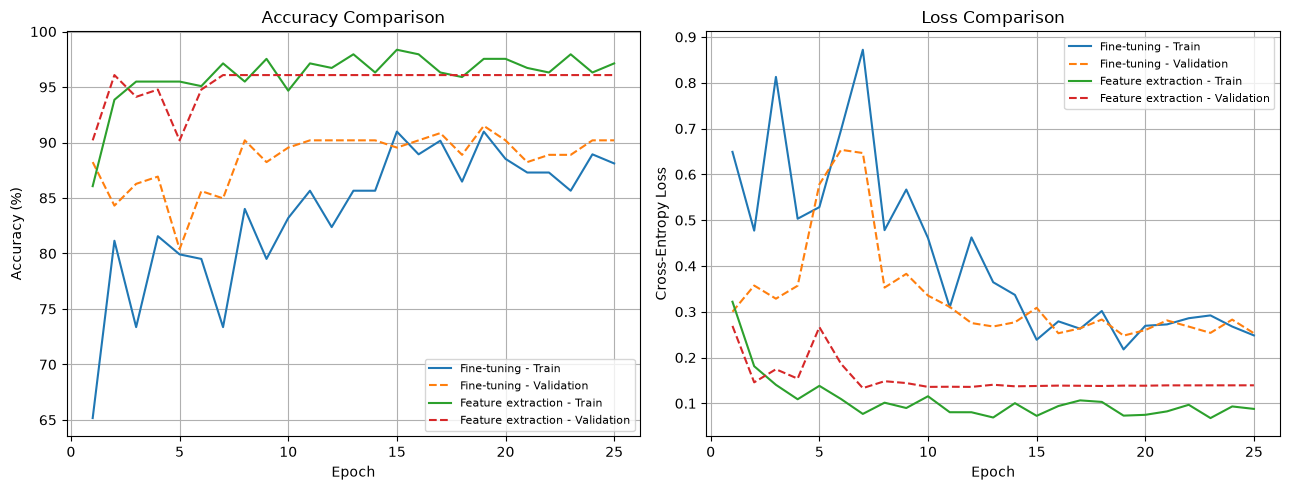

In [3]:
import copy, time, zipfile, urllib.request
from pathlib import Path
import torch, torch.nn as nn, torchvision, matplotlib.pyplot as plt
import torchvision.transforms as transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Download and load the Hymenoptera dataset
data_dir = Path("./data/hymenoptera_data")
if not data_dir.is_dir():
    zip_path = data_dir.with_suffix(".zip")
    zip_path.parent.mkdir(exist_ok=True)
    if not zip_path.exists():
        urllib.request.urlretrieve("https://download.pytorch.org/tutorial/hymenoptera_data.zip", zip_path)
    zipfile.ZipFile(zip_path).extractall(zip_path.parent)

normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
data_transforms = {
    "train": transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
                                 transforms.ToTensor(), normalize]),
    "val": transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(), normalize])}
image_datasets = {p: torchvision.datasets.ImageFolder(data_dir / p, data_transforms[p]) for p in ["train", "val"]}
dataloaders = {p: torch.utils.data.DataLoader(d, batch_size=4, shuffle=(p == "train")) for p, d in image_datasets.items()}
dataset_sizes = {p: len(d) for p, d in image_datasets.items()}
class_names = image_datasets["train"].classes
print("Classes:", class_names, "| Training images:", dataset_sizes["train"], "| Validation images:", dataset_sizes["val"])

# 2. Training and validation (SGD + StepLR as in the PyTorch tutorial; best epoch kept by val accuracy)
criterion, num_epochs = nn.CrossEntropyLoss(), 25

def train_model(model, name, params, feature_extractor=False):
    model.to(device)
    optimizer = torch.optim.SGD(params, lr=0.001, momentum=0.9)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
    history, best_acc, best_epoch, best_weights = [], 0.0, 0, copy.deepcopy(model.state_dict())
    start = time.time()
    for epoch in range(num_epochs):
        metrics = {}
        for phase in ["train", "val"]:
            # A frozen backbone stays in eval mode so its BatchNorm statistics are not updated
            model.train(phase == "train" and not feature_extractor)
            running_loss, running_corrects = 0.0, 0
            with torch.set_grad_enabled(phase == "train"):
                for x, y in dataloaders[phase]:
                    x, y = x.to(device), y.to(device)
                    outputs = model(x)
                    loss = criterion(outputs, y)
                    if phase == "train":
                        optimizer.zero_grad()
                        loss.backward()
                        optimizer.step()
                    running_loss += loss.item() * len(y)
                    running_corrects += (outputs.argmax(1) == y).sum().item()
            metrics[f"{phase}_loss"] = running_loss / dataset_sizes[phase]
            metrics[f"{phase}_acc"] = 100 * running_corrects / dataset_sizes[phase]
        if metrics["val_acc"] > best_acc:
            best_acc, best_epoch, best_weights = metrics["val_acc"], epoch + 1, copy.deepcopy(model.state_dict())
        history.append(metrics)
        scheduler.step()
        print(f"{name} | Epoch {epoch + 1:02d}/{num_epochs} | Train Loss: {metrics['train_loss']:.4f} | "
              f"Train Acc: {metrics['train_acc']:.2f}% | Val Loss: {metrics['val_loss']:.4f} | "
              f"Val Acc: {metrics['val_acc']:.2f}%")
    model.load_state_dict(best_weights)
    elapsed = time.time() - start
    print(f"\n{name}: Best validation accuracy = {best_acc:.2f}% at epoch {best_epoch}\n"
          f"Training time: {elapsed / 60:.2f} minutes\n")
    return model, history, best_epoch, elapsed

def resnet18(freeze):
    model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)  # ImageNet-1K
    for param in model.parameters():
        param.requires_grad = not freeze
    model.fc = nn.Linear(model.fc.in_features, len(class_names))  # new trainable 2-class head
    return model

# 3. (a) Fine-tuning: all ResNet18 layers are updated
model_ft = resnet18(freeze=False)
model_ft, history_ft, best_epoch_ft, time_ft = train_model(model_ft, "Fine-tuning", model_ft.parameters())

# 4. (b) Feature extraction: backbone frozen, only the final fc layer is trained
model_fe = resnet18(freeze=True)
model_fe, history_fe, best_epoch_fe, time_fe = train_model(
    model_fe, "Feature extraction", model_fe.fc.parameters(), feature_extractor=True)

# 5. Compare the best validation results
results = {"Fine-tuning": (history_ft, best_epoch_ft, time_ft),
           "Feature extraction": (history_fe, best_epoch_fe, time_fe)}
print("=" * 76 + "\nFINAL COMPARISON\n" + "=" * 76)
print(f"{'Method':<22}{'Best Epoch':>12}{'Train Acc':>13}{'Val Acc':>12}{'Time (min)':>14}")
for name, (history, best_epoch, elapsed) in results.items():
    m = history[best_epoch - 1]
    print(f"{name:<22}{best_epoch:>12}{m['train_acc']:>12.2f}%{m['val_acc']:>11.2f}%{elapsed / 60:>13.2f}")

# 6. Plot training and validation curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, (history, _, _) in results.items():
    for ax, metric in zip(axes, ["acc", "loss"]):
        ax.plot(range(1, num_epochs + 1), [h[f"train_{metric}"] for h in history], label=f"{name} - Train")
        ax.plot(range(1, num_epochs + 1), [h[f"val_{metric}"] for h in history], "--", label=f"{name} - Validation")
for ax, title, ylabel in zip(axes, ["Accuracy Comparison", "Loss Comparison"], ["Accuracy (%)", "Cross-Entropy Loss"]):
    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.legend(fontsize=8)
    ax.grid(True)
plt.tight_layout()
plt.show()

# 7. Save the best checkpoints
torch.save(model_ft.state_dict(), "resnet18_finetuned.pth")
torch.save(model_fe.state_dict(), "resnet18_feature_extractor.pth")

**Results.** Both runs use the tutorial setup: SGD (lr = 0.001, momentum 0.9), learning rate × 0.1 every 7 epochs, batch size 4, 25 epochs. The epoch with the best validation accuracy is kept.

| Method | Trainable params | Best epoch | Train Acc | Best Val Acc | Time |
|---|---|---|---|---|---|
| (a) Fine-tuning | 11,177,538 | 19 | 90.98% | 91.50% (140/153) | 3.54 min |
| (b) Feature extraction | 1,026 | 2 | 93.85% | **96.08%** (147/153) | 4.12 min |

**Discussion.**

- **Feature extraction performs better.** ImageNet-1K already includes ant and bee classes, so the frozen features suit this task and a new linear layer is enough. It reaches 96.08% by epoch 2.
- **Fine-tuning is unstable on so little data.** With only 244 images and batch size 4, updating all 11.2M weights is noisy: training loss spikes at epochs 3 and 7, and validation accuracy drops to 80.39% at epoch 5. This partly overwrites the pre-trained features. Batch normalisation also re-estimates its statistics from batches of only 4 images. Fine-tuning stabilises only after the learning-rate drops, and then settles around 90%.
- **Training vs validation accuracy:** fine-tuning's training accuracy is below its validation accuracy because training images are randomly cropped and flipped, and batch normalisation is in training mode.
- **Timing:** feature extraction needs far less computation, but it was not faster here (4.12 vs 3.54 min), because image loading on the CPU dominates the run time.
- **Caveat:** the best epoch is chosen on the same 153-image validation set that is reported (one image = 0.65%), so the accuracies are slightly optimistic.

**Conclusion.** For a small dataset similar to ImageNet, feature extraction is more stable and more accurate. Fine-tuning pays off with more data, or with a lower learning rate for the pre-trained layers.